In [2]:
from shapely import Point, LineString, Polygon
import geopandas as gpd

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

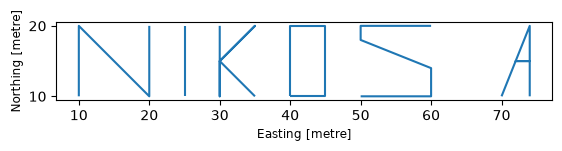

In [10]:
#Stwórz warstwę liniową, która po wyświetleniu będzie zawierała pierwsze 3 drukowane litery 
# Twojego imienia i pierwsze 3 drukowane litery Twojego nazwiska. 
# Każda literka powinna być osobnym rekordem w GeoDataFrame. Wyeksportuj te dane i wyświetl w QGIS.

n = LineString([(10, 10), (10, 20), (20,10), (20,20)])

i = LineString([(25, 20),(25, 10)])

k = LineString([(30, 20), (30, 15),(35, 20),(30,15), (30, 10), (30, 15), (35,10)])
o = LineString([(45, 20), (45, 10), (40, 10), (40, 20), (45, 20)])

s = LineString([(60, 20),(50, 20), (50, 18), (60,14), (60,10),(50, 10)])

a = LineString([(70, 10), (72, 15), (74, 15),(74,20), (72,15), (74,15), (74, 10)])

#k = LineString([(40, 20)()])
gdf4 = gpd.GeoDataFrame(
    {
        "name": ["poligon", "polgon2", "polygon3", "poligon4", "polygon5", "polygon6"]
    },
    geometry=[n, i, k, o, s, a],
    crs="EPSG:2180"
)

gdf4.plot()

#gdf4.to_file("C:\\Users\\nikit\\Nikita-Osaula---Struktury-Danych\\raster\\ttt\\test.geojson") 

In [9]:
wyspy = gpd.read_file("D:\\Statystyka przestrzenna\\fw2.geojson")
#print(wyspy)


slownik = {}

for country, group in wyspy.groupby("państwo"):
    slownik[country] = list(group.geometry)



wyspy_metry = wyspy.to_crs("EPSG:3875")

ranking = (wyspy_metry.groupby("państwo")["geometry"]
           .apply(lambda g: g.area.sum())
           .sort_values(ascending=False)
            .head(10))

print(ranking)


państwo
Indonezja                          6.854667e+12
Ekwador                            4.373835e+12
Filipiny                           3.497063e+12
Indonezja, Papua-Nowa Gwinea       3.320725e+12
Dania (terytorium autonomiczne)    2.338583e+12
Kanada                             1.604631e+12
Madagaskar                         7.081295e+11
Haiti, Dominikana                  6.416545e+11
Japonia                            6.384703e+11
Kuba                               6.289484e+11
Name: geometry, dtype: float64


c:\Users\nikit\AppData\Local\Programs\Python\Python312\Lib\site-packages\shapely\measurement.py:48: RuntimeWarning: invalid value encountered in area
  return lib.area(geometry, **kwargs)


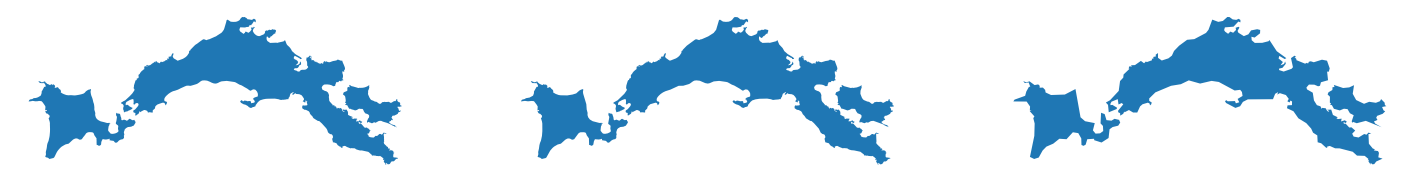

In [15]:
import matplotlib.pyplot as plt
wyspy_japonia = wyspy_metry[wyspy_metry["państwo"] == "Japonia"]



geoexploded_japonia = wyspy_japonia.explode(index_parts=False)

japonia_0 = geoexploded_japonia.copy()

japonia_1000 = geoexploded_japonia.copy()
japonia_1000["geometry"] = japonia_1000.geometry.simplify(tolerance=1000)

japonia_5000 = geoexploded_japonia.copy()
japonia_5000["geometry"] = japonia_5000.geometry.simplify(tolerance=5000)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))

japonia_0.plot(ax=ax[0]).set_axis_off()
japonia_1000.plot(ax=ax[1]).set_axis_off()
japonia_5000.plot(ax=ax[2]).set_axis_off()
 

In [16]:
from shapely import get_num_coordinates , get_num_interior_rings

punkty_0 = get_num_coordinates(japonia_0.geometry).sum()
punkty_1000 = get_num_coordinates(japonia_1000.geometry).sum()
punkty_5000 = get_num_coordinates(japonia_5000.geometry).sum()

print(f"liczba punktow_0: {punkty_0}")
print(f"liczba punktow_1000: {punkty_1000}")
print(f"liczba punktow_5000: {punkty_5000}")

ilosc_pierscieni_0 = (1 + get_num_interior_rings(japonia_0.geometry)).sum()
linie_0 = punkty_0 - ilosc_pierscieni_0
print(f"licba linii_0:{linie_0}")

ilosc_pierscieni_1000 = (1 + get_num_interior_rings(japonia_1000.geometry)).sum()
linie_1000 = punkty_1000 - ilosc_pierscieni_1000
print(f"licba linii_1000:{linie_1000}")

ilosc_pierscieni_5000 = (1 + get_num_interior_rings(japonia_5000.geometry)).sum()
linie_5000 = punkty_5000 - ilosc_pierscieni_5000
print(f"licba linii_5000:{linie_5000}")



liczba punktow_0: 55624
liczba punktow_1000: 1049
liczba punktow_5000: 366
licba linii_0:55621
licba linii_1000:1046
licba linii_5000:363
